# The Box Game

There is a 1000 x 1000 grid and a hidden treasure at `true_treasure` which you want to find.

Every week you move to a position in the grid and an _oracle_ gives you the distance to the treasure with a 10% error.

Here we'll use Numpyro to locate it.

In [1]:
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

import matplotlib.pyplot as plt

key = jax.random.PRNGKey(1234)

/home/carlos/gits/otros/datanalytics_code/2026-box-game/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initial point and error.

The defined `sd` will generate an error less than 10% with a confidence of 95%.

In [2]:

true_treasure = jnp.array([320.0, 750.0])
sd_error = .05 # 95% confidence in a 10% error

## Model + Random Approach 

Here 

$$d_o / d_r \sim \text{Norm}(1, \sigma)$$

where $d_o$ and $d_r$ are the observed and real distances between a location and the treasure.

The prior is uniform on a 1000 x 1000 canvas.

In [3]:

def model(visited_locations, observed_distances):
    """
    visited_locations: (N, 2) array of (x, y) coordinates visited
    observed_distances: (N,) array of noisy distance measurements
    """

    # Constants
    obs_sd = sd_error

    # Prior: treasure location uniform on [0, 1000] x [0, 1000]
    tx = numpyro.sample("tx", dist.Uniform(0, 1000))
    ty = numpyro.sample("ty", dist.Uniform(0, 1000))

    treasure = jnp.array([tx, ty])

    real_distances = jnp.sqrt(jnp.sum((visited_locations - treasure) ** 2, axis=1))

    numpyro.sample(
        "obs",
        dist.LogNormal(jnp.log(real_distances), obs_sd),
        obs=observed_distances
    )

First we generate a number of random points to see whether the process can locate the treasure using a _random_ approach. 

In [4]:
N = 20
key, k1, k2, k3 = jax.random.split(key, 4)
visited_locations = jax.random.uniform(k1, shape=(N, 2), minval=0, maxval=1000)
true_distances = jnp.sqrt(jnp.sum((visited_locations - true_treasure) ** 2, axis=1))
observed_distances = true_distances * (1 + sd_error *jax.random.normal(k2, shape=true_distances.shape))

In [5]:
nuts_kernel = NUTS(model)
mcmc = MCMC(nuts_kernel, num_warmup=1000, num_samples=2000, num_chains=2)
mcmc.run(k3, visited_locations, observed_distances)
mcmc.print_summary()

samples = mcmc.get_samples()
print('-----------------------------------------------------')
print(f"True treasure:      {true_treasure}")
print(f"Posterior mean tx:  {samples['tx'].mean():.2f}")
print(f"Posterior mean ty:  {samples['ty'].mean():.2f}")
print('-----------------------------------------------------')

/tmp/ipykernel_100051/386637415.py:2: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(nuts_kernel, num_warmup=1000, num_samples=2000, num_chains=2)
sample: 100%|██████████| 3000/3000 [00:00<00:00, 3478.74it/s, 3 steps of size 8.39e-01. acc. prob=0.90]



                mean       std    median      5.0%     95.0%     n_eff     r_hat
        tx    322.70      3.25    322.64    317.93    328.72   2384.12      1.00
        ty    743.11      6.98    743.48    731.90    754.69   1940.31      1.00

Number of divergences: 0
-----------------------------------------------------
True treasure:      [320. 750.]
Posterior mean tx:  322.70
Posterior mean ty:  743.11
-----------------------------------------------------


## Targeted Approach

Here, we'll move towards the target as new information comes in.

We'll start from a random position, calculate, move towards the most likely position, and iterate.

For that purpose, we'll create the next two functions that embed the process above.

In [6]:
def reported_distance(location, treasure, k):
    new_key, subkey = jax.random.split(k)
    noise = jax.random.normal(subkey, shape=()) * sd_error
    distance = jnp.sqrt(jnp.sum((location - treasure) ** 2))
    observed_distance = distance * (1 + noise)
    return observed_distance, new_key

In [7]:
def get_posterior(visited_locations, observed_distances, key, init_loc=None):
    nuts_kernel = NUTS(model)
    new_key, subkey = jax.random.split(key)

    mcmc = MCMC(nuts_kernel, num_warmup=1000, num_samples=2000, num_chains=1)

    if init_loc is not None:
        init_params = {"tx": jnp.array(init_loc[0]), "ty": jnp.array(init_loc[1])}
        mcmc.run(subkey, visited_locations, observed_distances, init_params=init_params)
    else:
        mcmc.run(subkey, visited_locations, observed_distances)

    mcmc.print_summary()
    samples = mcmc.get_samples()
    return samples, new_key

Main loop: starting with a _random_ position, we'll iteratively move towards the _most likely_ treasure position.

In [8]:
results = {}

new_key = key

for i in range(20):

    if i == 0:
        new_point = jnp.array([500.0, 500.0])
    else:
        prev_results = results[i - 1]
        new_point = jnp.array([prev_results['samples']['tx'].mean(), prev_results['samples']['ty'].mean()])

    new_distance, new_key = reported_distance(new_point, true_treasure, new_key)

    results[i] = {
        'point': new_point,
        'distance' : new_distance
    }

    visited_locations  = jnp.vstack([r['point'] for r in results.values()])
    observed_distances = jnp.stack([r['distance'] for r in results.values()])


    results[i]['samples'], new_key = get_posterior(visited_locations, observed_distances, new_key)

sample: 100%|██████████| 3000/3000 [00:03<00:00, 828.47it/s, 3 steps of size 7.83e-02. acc. prob=0.94]   



                mean       std    median      5.0%     95.0%     n_eff     r_hat
        tx    493.63    211.13    479.86    191.34    795.23    575.89      1.01
        ty    522.47    221.35    537.42    207.03    815.79    444.45      1.00

Number of divergences: 0


sample: 100%|██████████| 3000/3000 [00:03<00:00, 785.12it/s, 1 steps of size 8.22e-02. acc. prob=0.88]  



                mean       std    median      5.0%     95.0%     n_eff     r_hat
        tx    470.48    213.82    447.45    197.28    778.37    294.97      1.00
        ty    633.86    161.38    678.59    371.52    821.07    423.46      1.00

Number of divergences: 0


sample: 100%|██████████| 3000/3000 [00:02<00:00, 1001.48it/s, 15 steps of size 8.14e-02. acc. prob=0.95]



                mean       std    median      5.0%     95.0%     n_eff     r_hat
        tx    430.31    128.42    382.06    269.95    608.00     71.20      1.00
        ty    767.91     38.95    775.46    705.37    823.82    137.52      1.00

Number of divergences: 0


... (30 outputs left out)

sample: 100%|██████████| 3000/3000 [00:11<00:00, 260.13it/s, 1023 steps of size 6.12e-08. acc. prob=0.80]



                mean       std    median      5.0%     95.0%     n_eff     r_hat
        tx    319.82      0.00    319.82    319.82    319.82      1.00      1.00
        ty    750.00      0.00    750.00    750.00    750.00      1.00      1.00

Number of divergences: 0


sample: 100%|██████████| 3000/3000 [00:12<00:00, 242.95it/s, 1023 steps of size 2.42e-08. acc. prob=0.80]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
        tx    320.02      0.00    320.02    320.02    320.02      1.00      1.00
        ty    750.00      0.00    750.00    750.00    750.00      1.00      1.00

Number of divergences: 0


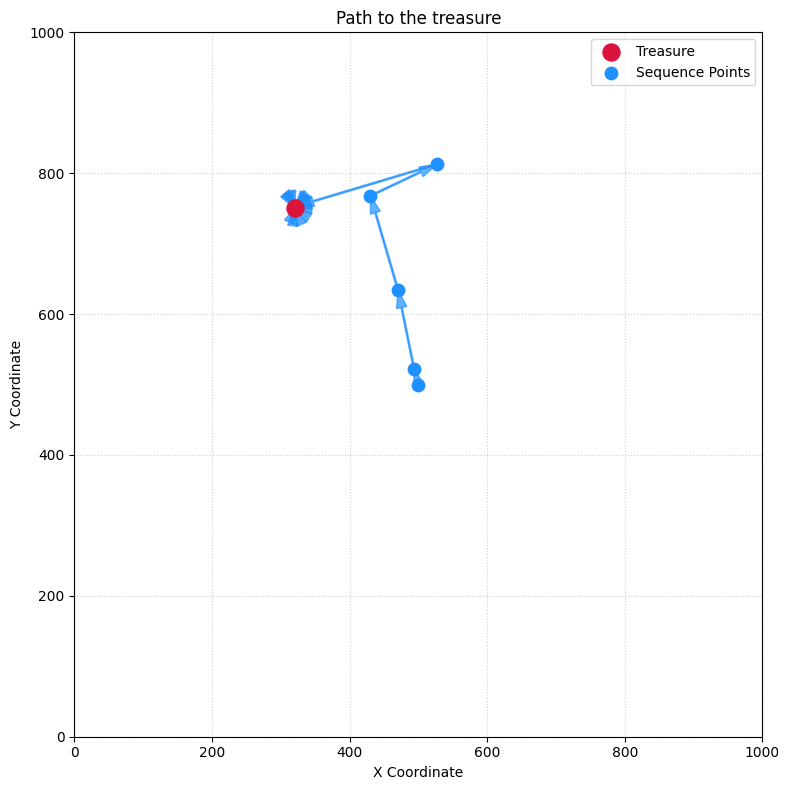

In [9]:
point = true_treasure

path = jnp.vstack([r['point'] for r in results.values()])


plt.figure(figsize=(8, 8))

# Set the canvas limits (1000 x 1000)
plt.xlim(0, 1000)
plt.ylim(0, 1000)

# 2. Plot the first point in a distinct color
plt.scatter(point[0], point[1], color='crimson', s=150, label='Treasure', zorder=5)

# 3. Plot the other points and join them with arrows
x_coords = path[:, 0]
y_coords = path[:, 1]

# Plot dots for the sequence points
plt.scatter(x_coords, y_coords, color='dodgerblue', s=80, label='Sequence Points', zorder=4)


for i in range(len(path) - 1):
    x_start, y_start = path[i]
    x_end, y_end = path[i+1]

    dx = x_end - x_start
    dy = y_end - y_start

    # plt.arrow draws the connection
    plt.arrow(x_start, y_start, dx, dy,
                head_width=15,          # Width of the arrow head
                head_length=25,         # Length of the arrow head
                fc='dodgerblue',        # Face color
                ec='dodgerblue',        # Edge color
                length_includes_head=True, # Tip ends exactly at the point
                alpha=0.7,
                width=2)                # Line thickness

# Aesthetics
plt.title("Path to the treasure")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()